# HMMploidy: models, benchmarks and real-data usage

This notebook documents how `hmmploidy` infers ploidy, and measures how its models behave when
sequencing data are overdispersed. It is self-contained: all data are simulated in a temporary
directory.

1. [How the model works](#1.-How-the-model-works): windows, emissions, and the four model choices
2. [A quick run](#2.-A-quick-run): simulate, compute genotype likelihoods, infer ploidy
3. [Benchmark under overdispersion](#3.-Benchmark-under-overdispersion)
4. [Known limitations](#4.-Known-limitations)
5. [Speed](#5.-Speed)
6. [BAM input](#6.-BAM-input)
7. [Recommendations for real data](#7.-Recommendations-for-real-data)

Run it with the `hmmploidy` conda environment
(`conda env create -f environment.yml && conda activate hmmploidy`). The full notebook takes a
few minutes, most of it in the benchmark of section 3.

In [1]:
import os
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hmmploidy import benchmark, data as dm, hmm, simulate
from hmmploidy import genotype_likelihoods as gl

WORKDIR = tempfile.mkdtemp(prefix="hmmploidy_nb_")
THREADS = min(8, os.cpu_count() or 1)
print("Working directory:", WORKDIR)

# One fixed colour per model (never re-assigned), reference palette slots 1-3.
MODEL_COLORS = {"overdispersed": "#2a78d6", "negbinom": "#eb6834", "em": "#1baf7a"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

Working directory: /var/folders/5m/2vk2v44j7rd27dd0wdmhyfhc0000gn/T/hmmploidy_nb_ko12heg9


## 1. How the model works

### Windows and hidden states

Each individual is analysed separately. Its sites are grouped into **windows** along each
chromosome (`--wind` base pairs; windows without any SNP are merged into a neighbour). The
Hidden Markov Model has one hidden state per candidate ploidy $k = 1, \dots, K$
(`--maxPloidy`), and the ploidy of consecutive windows is linked by a $K\times K$ transition
matrix. Two pieces of evidence are observed in every window $t$:

* the **mean read depth** $x_t$ of the window, and
* the **allele read counts** at its SNPs: minor-allele reads $m_i$ out of $n_i$ reads at SNP $i$.

The emission probability of window $t$ under ploidy $k$ is the product of a depth term and a
genotype-likelihood term:

$$
\log P(\text{window } t \mid k) = \log P(x_t \mid k) + \sum_{i \in t} \log \sum_{g=0}^{k}
P(g \mid k, f_i)\, P(m_i, n_i \mid g, k),
$$

where $g$ is the unknown dosage (number of copies of the minor allele) and $f_i$ is the
population minor-allele frequency. The ploidy path is decoded with Viterbi; posterior ploidy
probabilities come from forward-backward.

### SNP selection

SNPs are the sites whose **population** allele frequency is within `--SNPtrim` (default
0.1-0.9), as in the original `HMMploidy.R`. (An earlier version of the Python port selected
sites where the *individual* looked heterozygous. High ploidies are heterozygous more often,
so that choice pushed every call towards the highest ploidy.)

### Why overdispersion matters

Both evidence types are *more variable* in real data than simple sampling models predict:

* **Depth** varies between regions because of GC content, mappability, and library effects.
  This regional bias does not average out within a window.
* **Allele ratios** at heterozygous sites spread beyond Binomial noise (reference mapping bias,
  PCR duplicates, mapping errors), or are systematically shifted (reference bias).

The genotype-likelihood term is a **sum over all SNPs of a window**, so a model that is only
slightly too confident per SNP becomes very confident, and wrong, per window.

### The four models (`hmmploidy run --model ...`)

| Model | Depth emission | Allele-count likelihood | Fitting |
|---|---|---|---|
| `overdispersed` (default) | Gamma, mean $k\cdot h$ with one shared haploid depth $h$, plus a 1% outlier component | **Beta-Binomial** with overdispersion $\rho$ estimated from the data | EM; $\rho$ by profile likelihood |
| `negbinom` | Negative Binomial, free mean per state | Binomial, per-read base qualities | EM with Newton-Raphson (original R method) |
| `em` | Poisson, free mean per state | Binomial, per-read base qualities | EM, closed form |
| `bayesian` | Negative Binomial, mean $k\cdot h$ | Binomial, per-read base qualities | PyMC / NUTS sampling |

**`negbinom`** is the translation of the original `HMMploidy.R`. Each ploidy state gets its own
depth distribution, and the precomputed genotype likelihoods (from per-read base qualities) are
added as a fixed term.

**`em`** replaces the Negative Binomial with a Poisson, so the M-step is closed form. It is fast,
but it models neither kind of overdispersion.

**`bayesian`** ties the depth means to one haploid depth and samples all parameters with NUTS.
It needs PyMC and a working PyTensor compiler, and it is much slower than the EM models. It is
therefore off by default in this notebook (`RUN_BAYESIAN` below).

**`overdispersed`** computes its own genotype likelihoods from the allele counts:

* **Beta-Binomial allele counts.** Given dosage $g$ out of $k$ copies, minor-allele reads are
  $m_i \sim \text{BetaBinomial}(n_i, \pi_g, \rho)$, with mean $\pi_g \approx g/k$ (corrected for
  sequencing error, estimated from reads showing a third allele) and intra-class correlation
  $\rho$. At $\rho = 0$ this is the Binomial model. $\rho$ is chosen from a grid by maximising the
  (penalised) HMM likelihood, so it is fitted per individual rather than assumed.
* **Frequency prior with uncertainty.** The dosage prior uses a frequency estimated from the
  *other* individuals (leave-one-out), integrated over its Beta uncertainty:
  $P(g \mid k) = \text{BetaBinomial}(g;\,k, a_i, b_i)$. Including the individual's own reads
  lets a deep sample dominate its own prior in small cohorts, which biases calls upwards. The
  uncertainty caps the evidence at 2 chromosomes per other individual, because reads from the
  same individual are not independent allele draws.
* **Depth proportional to ploidy.** $x_t \sim \text{Gamma}(\text{mean}=k h, \text{shape}=a)$.
  The variance grows with the square of the mean, like regional coverage bias. $h$ has a
  closed-form M-step and $a$ a 1-D Newton step. A small uniform outlier component absorbs
  repeat or collapsed-duplication windows.
* **Sticky transitions.** A Dirichlet prior adds $0.2\,T$ pseudo-counts to self-transitions
  ($T$ = number of windows). Without it, the model can switch rapidly between neighbouring
  ploidies (4 ↔ 5) to explain coverage noise.
* **Scale ambiguity.** Depth alone cannot tell "2 copies at depth $h$" from "4 copies at
  $h/2$". The fit is therefore restarted from every whole-genome ploidy, and the best penalised
  likelihood wins.

## 2. A quick run

Six individuals, three genome segments of 15,000 loci, haploid depth 5×. The first three
individuals are 2 → 4 → 3 along the genome, the last three 3 → 2 → 4. The data are simulated
with all kinds of overdispersion at once (the `hard` scenario of section 3).

In [2]:
demo_dir = os.path.join(WORKDIR, "demo")
segments = benchmark.ploidy_layout("changing", 6)
gl_path = benchmark.simulate_scenario("hard", demo_dir, depth=5.0, threads=THREADS)
print("genotype likelihoods:", gl_path)
print(pd.DataFrame(segments, index=["segment 1", "segment 2", "segment 3"],
                   columns=[f"ind{i}" for i in range(1, 7)]))

genotype likelihoods: /var/folders/5m/2vk2v44j7rd27dd0wdmhyfhc0000gn/T/hmmploidy_nb_ko12heg9/demo/hard.changing.DP5.0.genolikes.gz
           ind1  ind2  ind3  ind4  ind5  ind6
segment 1     2     2     2     3     3     3
segment 2     4     4     4     2     2     2
segment 3     3     3     3     4     4     4


In [3]:
from hmmploidy import run as hmm_run

RUN_BAYESIAN = False  # slow (minutes per individual) and needs a working PyTensor compiler
models = ["overdispersed", "negbinom", "em"] + (["bayesian"] if RUN_BAYESIAN else [])
results = {}
for model in models:
    t0 = time.perf_counter()
    results[model] = hmm_run.analyze_file(
        gl_path, out_prefix=os.path.join(demo_dir, f"demo.{model}"), model=model,
        wind=100, max_ploidy=6, plot=False,
    )
    print(f"{model:14s} {time.perf_counter() - t0:5.1f} s for 6 individuals")

[ind1] done: 450 windows
[ind2] done: 450 windows


[ind3] done: 450 windows
[ind4] done: 450 windows


[ind5] done: 450 windows
[ind6] done: 450 windows
overdispersed    1.1 s for 6 individuals


[ind1] done: 450 windows
[ind2] done: 450 windows


[ind3] done: 450 windows
[ind4] done: 450 windows


[ind5] done: 450 windows
[ind6] done: 450 windows
negbinom         1.0 s for 6 individuals


[ind1] done: 450 windows
[ind2] done: 450 windows
[ind3] done: 450 windows
[ind4] done: 450 windows
[ind5] done: 450 windows
[ind6] done: 450 windows
em               0.2 s for 6 individuals


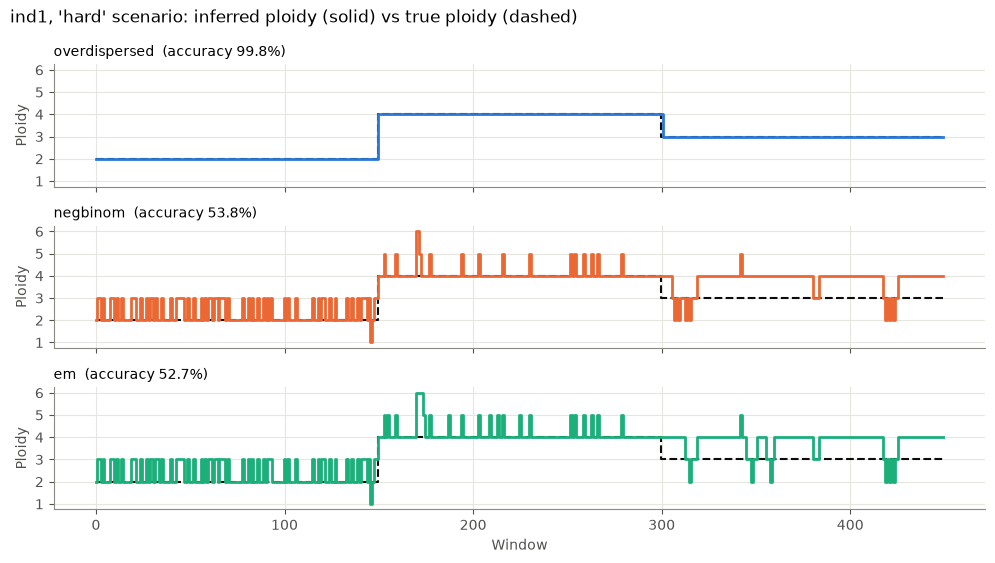

overdispersed  accuracy=0.998  rho=0.10  haploid depth=4.77
negbinom       accuracy=0.538
em             accuracy=0.527


In [4]:
ind = 1
res0 = results["overdispersed"][ind - 1]
centre = (res0["window_start"] + res0["window_end"]) / 2
truth = np.array([segments[k][ind - 1] for k in np.clip((centre - 1) // 15000, 0, 2).astype(int)])

fig, axes = plt.subplots(len(models), 1, figsize=(10, 1.9 * len(models)), sharex=True, sharey=True)
for ax, model in zip(np.atleast_1d(axes), models):
    states = results[model][ind - 1]["states"]
    ax.step(np.arange(len(truth)), truth, where="mid", color="#0b0b0b", lw=1.5, ls="--")
    ax.step(np.arange(len(states)), states, where="mid", color=MODEL_COLORS.get(model, "#4a3aa7"), lw=2)
    ax.set_title(f"{model}  (accuracy {np.mean(states == truth):.1%})", loc="left", fontsize=10)
    ax.set(ylabel="Ploidy", yticks=range(1, 7))
np.atleast_1d(axes)[-1].set_xlabel("Window")
fig.suptitle(f"ind{ind}, 'hard' scenario: inferred ploidy (solid) vs true ploidy (dashed)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

for model in models:
    r = results[model][ind - 1]
    extra = f"  rho={r['rho']:.2f}  haploid depth={r['haploid_depth']:.2f}" if model == "overdispersed" else ""
    print(f"{model:14s} accuracy={np.mean(r['states'] == truth):.3f}{extra}")

## 3. Benchmark under overdispersion

Each scenario below is simulated with `hmmploidy simulate`, processed with
`hmmploidy genolikes`, and fitted with every model. The score is the fraction of windows whose
ploidy is called correctly, averaged over individuals. The worst individual is shown in the
tables. Scenario definitions live in `hmmploidy.benchmark.SCENARIOS`, so they can be reused
outside this notebook.

In [5]:
pd.DataFrame(
    [(name, s.description, s.sim_kwargs) for name, s in benchmark.SCENARIOS.items()],
    columns=["scenario", "description", "simulator options"],
).set_index("scenario")

,description,simulator options
scenario,,
poisson,"Poisson depth, Binomial allele counts (no over...",{'depth_model': 'poisson'}
nb1,Strongly overdispersed per-site depth (NB size 1),"{'depth_model': 'negbinom', 'dispersion': 1.0}"
cv30,"Regional coverage bias, CV 30% over 50-locus b...","{'depth_model': 'negbinom', 'dispersion': 5.0,..."
ab05,"Beta-Binomial allele counts, rho = 0.05","{'depth_model': 'negbinom', 'dispersion': 5.0,..."
ab15,"Beta-Binomial allele counts, rho = 0.15","{'depth_model': 'negbinom', 'dispersion': 5.0,..."
refbias,Reference bias: non-reference reads under-samp...,"{'depth_model': 'negbinom', 'dispersion': 5.0,..."
hard,All combined: NB size 2 + regional CV 30% + rh...,"{'depth_model': 'negbinom', 'dispersion': 2.0,..."
hardrb,'hard' + reference bias (odds 0.8),"{'depth_model': 'negbinom', 'dispersion': 2.0,..."


In [6]:
bench_dir = os.path.join(WORKDIR, "bench")
t0 = time.perf_counter()
runs = [
    benchmark.run_benchmark(list(benchmark.SCENARIOS), bench_dir, depth=5.0, threads=THREADS),
    benchmark.run_benchmark(["poisson", "ab15", "hard", "hardrb"], bench_dir, depth=2.0, threads=THREADS),
    benchmark.run_benchmark(["poisson", "hard", "hardrb"], bench_dir, depth=5.0, layout="uniform",
                            threads=THREADS),
]
bench = pd.concat(runs, ignore_index=True)
bench["condition"] = np.where(
    bench["layout"] == "uniform", "5x, one ploidy per individual",
    np.where(bench["depth"] == 2.0, "2x, ploidy changes", "5x, ploidy changes"),
)
print(f"benchmark finished in {time.perf_counter() - t0:.0f} s")

benchmark finished in 93 s


In [7]:
summary = (bench.groupby(["condition", "scenario", "model"], sort=False)["accuracy"]
           .agg(mean="mean", worst="min").unstack("model"))
summary = summary.reindex(columns=["overdispersed", "negbinom", "em"], level=1)
summary.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0.5, vmax=1.0)

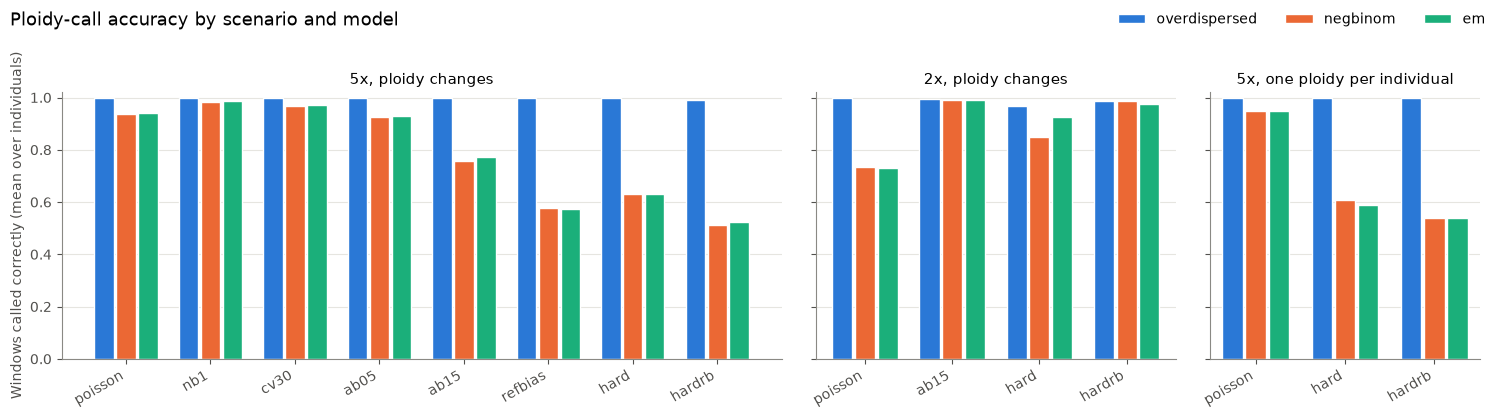

In [8]:
conditions = list(dict.fromkeys(bench["condition"]))
model_order = ["overdispersed", "negbinom", "em"]
fig, axes = plt.subplots(1, len(conditions), figsize=(15, 4.2), sharey=True,
                         gridspec_kw={"width_ratios": [bench.loc[bench.condition == c, "scenario"].nunique()
                                                       for c in conditions]})
width = 0.26
for ax, cond in zip(axes, conditions):
    sub = bench[bench.condition == cond].groupby(["scenario", "model"], sort=False)["accuracy"].mean().unstack()
    x = np.arange(len(sub))
    for j, model in enumerate(model_order):
        ax.bar(x + (j - 1) * width, sub[model], width=width - 0.03, color=MODEL_COLORS[model],
               label=model, edgecolor="white", linewidth=1)
    ax.set_xticks(x, sub.index, rotation=30, ha="right")
    ax.set_title(cond, fontsize=11)
    ax.set_ylim(0, 1.02)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Windows called correctly (mean over individuals)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper right", ncol=3)
fig.suptitle("Ploidy-call accuracy by scenario and model", x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [9]:
est = bench[bench.model == "overdispersed"].groupby(["condition", "scenario"], sort=False)["rho"].median()
true_rho = {k: s.sim_kwargs.get("allele_overdispersion", 0.0) for k, s in benchmark.SCENARIOS.items()}
pd.DataFrame({"estimated rho (median)": est,
              "simulated rho": [true_rho[s] for _, s in est.index]}).round(3)

estimated rho (median)  simulated rho
condition                     scenario                                       
5x, ploidy changes            poisson                    0.000           0.00
                              nb1                        0.000           0.00
                              cv30                       0.000           0.00
                              ab05                       0.040           0.05
                              ab15                       0.150           0.15
                              refbias                    0.020           0.00
                              hard                       0.100           0.10
                              hardrb                     0.100           0.10
2x, ploidy changes            poisson                    0.005           0.00
                              ab15                       0.150           0.15
                              hard                       0.100           0.10
                              hardrb                     0.100           0.10
5x, one ploidy per individual poisson                    0.000           0.00
                              hard                       0.100           0.10
                              hardrb                     0.100           0.10

**Reading the results**

* Without overdispersion (`poisson`) all models do well at 5×, although the legacy models
  occasionally mislabel whole segments.
* **Allelic overdispersion and reference bias** (`ab15`, `refbias`, `hard`, `hardrb`) are what
  break the Binomial genotype likelihoods. The `overdispersed` model estimates $\rho$ close to
  the simulated value and stays near-perfect.
* With **one ploidy per individual** (uniform layout), depth only identifies ploidy up to the
  haploid-depth scale, and the legacy models often settle on the wrong scale.
* At **2× depth with heavy overdispersion** (`hard`, `hardrb`) the margin shrinks, and the
  worst individual can drop well below the mean. This is also the condition that varies most
  between simulation seeds: in other runs the legacy models were slightly ahead here. The
  reason is the leave-one-out frequency prior of the `overdispersed` model: at 2× the other
  individuals contribute few reads, so the prior is weak. The legacy models include each
  individual's own reads in its frequency, which helps in this homogeneous 6-sample simulation
  but biases calls in small cohorts with mixed depths (see the BAM example in section 6). This
  trade-off was accepted on purpose and not tuned away, to avoid fitting the method to its own
  simulator.
* These simulations share the `overdispersed` model's assumptions (Beta-Binomial allele
  counts, multiplicative coverage bias), so they are a best case for it. `refbias` is
  the one scenario that violates them. Validate on real data with known ploidy before trusting
  the calls.

## 4. Known limitations

### Short aneuploid segments

Below, a trisomic segment of about 5 or 15 windows sits in an otherwise diploid genome, under
the `hard` noise model, fitted with the default sticky prior (`0.2 × number of windows`) and a
ten times weaker one.

In [10]:
short_dir = os.path.join(WORKDIR, "short")
os.makedirs(short_dir, exist_ok=True)
with open(os.path.join(short_dir, "p.txt"), "w") as fh:
    fh.write("2x6\n3x6\n2x6\n")
rows = []
for mid in (500, 1500):
    prefix = os.path.join(short_dir, f"short{mid}")
    simulate.simulate_dataset(os.path.join(short_dir, "p.txt"), [20000, mid, 20000], [5.0], prefix,
                              seed=3, **benchmark.SCENARIOS["hard"].sim_kwargs)
    ns = gl.build_parser().parse_args(["-s", "3", "-t", str(THREADS)])
    gl.run_on_file(f"{prefix}.DP5.0.mpileup.gz", f"{prefix}.genolikes.gz", [1, 2, 3, 4, 5, 6], ns)
    df = dm.read_genolikes(f"{prefix}.genolikes.gz")
    pop = dm.population_counts(df)
    for ind in range(1, 7):
        iw = dm.prepare_individual(df, ind, tuple(range(1, 7)), 6, 100, pop=pop)
        c = (iw.window_start + iw.window_end) / 2
        inside = (c > 20000) & (c <= 20000 + mid)
        for label, kw in [("default sticky", {}), ("weak sticky (0.02 T)", {"sticky": 0.02 * len(iw.depth)})]:
            r = hmm.fit("overdispersed", iw.depth, iw.log_emission, snps=iw.snps, **kw)
            rows.append(dict(segment_windows=int(inside.sum()), prior=label,
                             trisomy_recall=np.mean(r["states"][inside] == 3),
                             diploid_accuracy=np.mean(r["states"][~inside] == 2)))
pd.DataFrame(rows).groupby(["segment_windows", "prior"]).mean().round(3)

trisomy_recall  diploid_accuracy
segment_windows prior                                                 
5               default sticky                 0.300               1.0
                weak sticky (0.02 T)           0.300               1.0
15              default sticky                 0.956               1.0
                weak sticky (0.02 T)           0.933               1.0

Segments of ~15 windows are found reliably, but ~5-window segments mostly are not, and a
weaker sticky prior does not help. With this much noise, a few windows simply do not carry
enough evidence to beat a ploidy change. To detect short events, use smaller windows (more
windows per event) or deeper sequencing, rather than a weaker prior.

### Other limitations

* **Few individuals.** Genotype likelihoods need population allele frequencies. With 1-2
  individuals these are very noisy (with a single individual, its own reads are used). Four or
  more individuals are recommended.
* **Window size.** `--wind` is in base pairs. Windows should hold enough SNPs (tens) for the
  allele evidence to discriminate between neighbouring high ploidies (5 vs 6).
* **The `bayesian` model** does not use the overdispersion-aware likelihood, and on some
  systems (e.g. recent macOS) PyTensor's C compiler fails to link.

## 5. Speed

### Genotype likelihoods

`hmmploidy genolikes` processes each mpileup line with a compiled numba kernel (decode,
quality filter, site filters and genotype likelihoods in one pass over the raw bytes). Chunks
of lines run in parallel worker processes (`--threads`), and each chunk is written as an
independent gzip member. The pure-Python implementation is kept as a reference
(`genotype_likelihoods.process_site`); the two agree to within $10^{-12}$.

In [11]:
import gzip, random

mp_path = os.path.join(bench_dir, "hard.changing.DP5.0.mpileup.gz")
lines = gzip.open(mp_path, "rt").read().splitlines()[:5000]
nsams = (len(lines[0].split("\t")) - 3) // 3
t0 = time.perf_counter()
for line in lines:
    gl.process_site(line, nsams, [1, 2, 3, 4, 5, 6], 1, 0.2, 0.1, 0.1, 0, -1, 1.0, random.Random(1))
t_ref = (time.perf_counter() - t0) / len(lines)

timings = []
for threads in sorted({1, THREADS}):
    ns = gl.build_parser().parse_args(["-s", "1", "-t", str(threads)])
    t0 = time.perf_counter()
    gl.run_on_file(mp_path, os.path.join(WORKDIR, "speed.genolikes.gz"), [1, 2, 3, 4, 5, 6], ns)
    timings.append((f"compiled kernel, {threads} process(es)",
                    (time.perf_counter() - t0) / (3 * 15000)))
timings.insert(0, ("pure-Python reference", t_ref))
speed = pd.DataFrame(timings, columns=["implementation", "seconds per site"])
speed["sites per second"] = (1 / speed["seconds per site"]).round(0)
speed["speed-up"] = (t_ref / speed["seconds per site"]).round(1)
speed

,implementation,seconds per site,sites per second,speed-up
0,pure-Python reference,0.000122,8229.0,1.0
1,"compiled kernel, 1 process(es)",0.000013,74215.0,9.0
2,"compiled kernel, 8 process(es)",0.000017,57904.0,7.0


The speed-up from extra processes grows with file size: a 45,000-site file is dominated by
start-up cost. On 360,000 sites × 6 individuals, 8 processes ran about 30× faster than the
original implementation.

### HMM fitting and window preparation

The forward-backward and Viterbi recursions are compiled with numba. Window construction is
vectorised: the original loop was quadratic in the number of candidate windows per contig, and
the contig loop was quadratic in the number of contigs. On a fragmented assembly (5,000
contigs, 400,000 SNPs, 10 individuals), preparation went from 85 s to 1.3 s per individual.
`hmmploidy run --threads N` fits individuals in parallel.

In [12]:
fit_times = bench.groupby("model")[["fit_seconds", "windows"]].mean()
fit_times["ms per 1000 windows"] = (1000 * fit_times["fit_seconds"] / fit_times["windows"] * 1000).round(1)
fit_times.round(3)

,fit_seconds,windows,ms per 1000 windows
model,,,
em,0.006,450.0,12.2
negbinom,0.096,450.0,213.2
overdispersed,0.116,450.0,257.0


## 6. BAM input

You do not need to produce mpileup files yourself. Give `hmmploidy genolikes` a text file listing
one BAM per individual:

```bash
hmmploidy genolikes --bamList bams.txt --ref_fasta reference.fa --outName mypop --threads 8
hmmploidy run --file mypop --nameFile mypop.names --wind 1000 --threads 8
```

* All BAMs are piled up **jointly** by `samtools mpileup` into one multi-sample `.genolikes.gz`,
  so allele frequencies are estimated from the whole population. The output is streamed: no
  intermediate mpileup file is written.
* If every BAM is indexed (`samtools index`), the genome is split into regions (`--region_size`,
  default 10 Mb) that are piled up and processed in parallel.
* Sample names (BAM file names) go to `<outName>.names`, which can be passed to `--nameFile`.
* `--min_mapq` sets the minimum mapping quality, and `--mpileup_args "..."` passes any other
  `samtools mpileup` option (e.g. `"-B"` to disable BAQ).
* Requires `samtools` (`conda install -c bioconda samtools`).

The cell below builds four small synthetic BAMs (ploidies 2, 2, 4 and 3) and runs the full BAM
workflow, if samtools is available.

In [13]:
import shutil, subprocess, sys

samtools = shutil.which("samtools") or shutil.which("samtools", path=os.path.dirname(sys.executable))
if samtools is None:
    print("samtools not found - skipping the BAM example")
else:
    bam_dir = os.path.join(WORKDIR, "bam")
    os.makedirs(bam_dir, exist_ok=True)
    rng = np.random.default_rng(7)
    contigs = {"chr1": 150_000, "chr2": 100_000}
    bam_ploidy = [2, 2, 4, 3]
    B = np.array(list("ACGT"))
    ref = {c: rng.integers(0, 4, L) for c, L in contigs.items()}
    with open(os.path.join(bam_dir, "ref.fa"), "w") as fh:
        for c, seq in ref.items():
            s = "".join(B[seq])
            fh.write(f">{c}\n" + "\n".join(s[i:i + 60] for i in range(0, len(s), 60)) + "\n")
    subprocess.run([samtools, "faidx", os.path.join(bam_dir, "ref.fa")], check=True)
    snp_pos = {c: np.sort(rng.choice(L, L // 50, replace=False)) for c, L in contigs.items()}
    freq = {c: rng.uniform(0.1, 0.9, len(snp_pos[c])) for c in contigs}
    alt = {c: (ref[c][snp_pos[c]] + rng.integers(1, 4, len(snp_pos[c]))) % 4 for c in contigs}
    bams = []
    for si, k in enumerate(bam_ploidy):
        name = f"sample{si + 1}"
        sam = ["@HD\tVN:1.6"] + [f"@SQ\tSN:{c}\tLN:{L}" for c, L in contigs.items()]
        for c, L in contigs.items():
            haps = np.tile(ref[c], (k, 1))
            carriers = rng.random((k, len(snp_pos[c]))) < freq[c]
            for h in range(k):
                haps[h, snp_pos[c][carriers[h]]] = alt[c][carriers[h]]
            for r, (st, h) in enumerate(zip(rng.integers(0, L - 100, L * k * 4 // 100),
                                            rng.integers(0, k, L * k * 4 // 100))):
                seq = "".join(B[haps[h, st:st + 100]])
                sam.append(f"{c}_{r}\t0\t{c}\t{st + 1}\t60\t100M\t*\t0\t0\t{seq}\t{'I' * 100}")
        sam_path = os.path.join(bam_dir, f"{name}.sam")
        open(sam_path, "w").write("\n".join(sam) + "\n")
        bam = os.path.join(bam_dir, f"{name}.bam")
        subprocess.run([samtools, "sort", "-o", bam, sam_path], check=True, capture_output=True)
        subprocess.run([samtools, "index", bam], check=True)
        os.remove(sam_path)
        bams.append(bam)
    with open(os.path.join(bam_dir, "bams.txt"), "w") as fh:
        fh.write("\n".join(bams) + "\n")

    gl.main(["--bamList", os.path.join(bam_dir, "bams.txt"), "--ref_fasta", os.path.join(bam_dir, "ref.fa"),
             "--outName", "mypop", "--threads", str(THREADS), "--region_size", "50000"])
    names = [l.strip() for l in open(os.path.join(bam_dir, "mypop.names"))]
    bam_res = hmm_run.analyze_file(os.path.join(bam_dir, "mypop.genolikes.gz"),
                                   os.path.join(bam_dir, "mypop"), wind=100, names=names, plot=False)
    print(pd.DataFrame({
        "sample": [r["name"] for r in bam_res],
        "true ploidy": bam_ploidy,
        "called ploidy (most common)": [int(np.bincount(r["states"]).argmax()) for r in bam_res],
        "fraction of windows": [float(np.bincount(r["states"]).max() / len(r["states"])) for r in bam_res],
    }).to_string(index=False))

Seed is not set.
Default ploidy levels to be tested in analysis are: [1, 2, 3, 4, 5, 6]
4 BAM file(s), piled up jointly (one sample each)
Output file is: /var/folders/5m/2vk2v44j7rd27dd0wdmhyfhc0000gn/T/hmmploidy_nb_ko12heg9/bam/mypop.genolikes.gz (sample names in /var/folders/5m/2vk2v44j7rd27dd0wdmhyfhc0000gn/T/hmmploidy_nb_ko12heg9/bam/mypop.names, usable as --nameFile)
Piling up 4 BAM files in 5 regions with 8 threads


[sample1] done: 1774 windows
[sample2] done: 1758 windows


[sample3] done: 1766 windows
[sample4] done: 1775 windows
 sample  true ploidy  called ploidy (most common)  fraction of windows
sample1            2                            2             1.000000
sample2            2                            2             1.000000
sample3            4                            4             1.000000
sample4            3                            3             0.989296


## 7. Recommendations for real data

* **Start from BAMs** with `--bamList`, index them, and use `--threads`. Filter duplicates
  upstream (samtools skips reads flagged as duplicates) and set `--min_mapq` (e.g. 20) to limit
  mapping artefacts.
* **Keep low-coverage sites.** `--min_ind_depth` now defaults to -1, so sites where some
  individuals have no reads are kept (their genotype likelihoods are uninformative). The old
  default dropped any site not covered in *every* individual, which removes almost everything
  with many low-coverage samples.
* **Soft-masked references** (lowercase bases) are handled: reference-matching reads are counted
  in either case.
* **Use four or more individuals**, so leave-one-out allele frequencies are informative.
* **Choose `--wind`** so that windows hold tens of SNPs. Check `allele_overdispersion_rho` and
  `haploid_depth` in the `.HMMploidy` output: a large $\rho$ (> 0.2) points to mapping problems
  or paralogs.
* **Compare models.** Agreement between `overdispersed` and the legacy models is reassuring;
  disagreement concentrated in regions of unusual depth suggests collapsed repeats or CNVs rather
  than ploidy.